# 01 · Machine learning foundations and NumPy

**CSE273 Unit I.** What machine learning is, the three kinds of learning, how models are categorised, the workflow, train/test evaluation, overfitting, the bias–variance trade-off, and NumPy for the numerical work underneath all of it.

The data throughout this project is the Kaggle **Playground Series S6E4, Predicting Irrigation Need**: 630,000 fields described by soil, weather and crop features, labelled with how much irrigation they need (Low, Medium, High). I entered this competition in April 2026 with a quick XGBoost model (balanced accuracy 0.960). This project goes back to the foundations under that model.

In [1]:
try:
    import groundwork
except ImportError:  # running on Kaggle
    %pip install -q git+https://github.com/LuShadowX/Groundwork
    import groundwork

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from groundwork import data, plotting
plotting.setup()

df = data.sample(20_000, seed=0)
df.head()

,id,Soil_Type,Soil_pH,Soil_Moisture,Organic_Carbon,Electrical_Conductivity,Temperature_C,Humidity,Rainfall_mm,Sunlight_Hours,...,Crop_Type,Crop_Growth_Stage,Season,Irrigation_Type,Water_Source,Field_Area_hectare,Mulching_Used,Previous_Irrigation_mm,Region,Irrigation_Need
0,286372,Loamy,6.22,55.76,0.46,2.31,33.49,30.33,2267.64,10.17,...,Potato,Flowering,Kharif,Rainfed,Rainwater,1.59,No,2.62,Central,Medium
1,281037,Clay,6.88,37.96,1.40,2.46,27.50,64.98,1407.34,6.24,...,Sugarcane,Sowing,Zaid,Rainfed,Rainwater,13.07,Yes,47.89,Central,Low
2,250842,Sandy,7.89,12.20,0.31,3.11,25.81,72.79,14.81,9.63,...,Cotton,Flowering,Rabi,Canal,Rainwater,6.77,No,49.09,South,Medium
3,35857,Sandy,5.03,50.29,0.40,3.31,35.16,45.39,1656.35,9.43,...,Cotton,Vegetative,Rabi,Canal,Groundwater,13.52,No,106.96,South,Medium
4,628778,Silt,5.21,48.66,1.47,0.76,36.68,27.96,1428.65,10.14,...,Sugarcane,Harvest,Kharif,Canal,Rainwater,14.95,No,107.24,East,Low


## 1. What machine learning is

Tom Mitchell's definition: a program **learns** from experience *E* with respect to a task *T* and a performance measure *P* if its performance at *T*, measured by *P*, improves with *E*. For this dataset:

| | |
|---|---|
| Task *T* | predict a field's irrigation need (Low / Medium / High) |
| Experience *E* | 630,000 labelled fields |
| Performance *P* | balanced accuracy (the competition metric: the mean of per-class recall) |

Instead of writing rules like "if soil moisture < 20 and temperature > 33 then High", the rules are learned from examples. That only pays off when the rules are hard to write by hand and there is enough data, both of which are true here.

## 2. AI vs machine learning vs data science

- **Artificial intelligence** is the broad goal: machines doing things that need intelligence. A hand-written rule system for irrigation is AI without any learning.
- **Machine learning** is the part of AI that learns the rules from data.
- **Data science** is the whole job around the data: collecting, cleaning, exploring, visualising, modelling and communicating. ML is one tool inside it.

Most of this project is data science (Units II–III) and the mathematics (Units IV–VI) that makes the ML part work.

## 3. Types of machine learning

- **Supervised:** examples come with the answer. Predicting `Irrigation_Need` is supervised *classification*; predicting `Soil_Moisture` from the other columns would be *regression*.
- **Unsupervised:** no answers. Finding groups of similar fields (clustering) is unsupervised.
- **Reinforcement learning:** an agent acts, gets a reward and learns a policy. An irrigation controller that waters, measures the crop and adjusts would be RL. There's no reward signal in a static dataset, so it is only described here.

One small example of each of the first two, on the same data:

In [2]:
from sklearn.cluster import KMeans
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

X_num, y = data.xy(df, numeric_only=True)
Xs = StandardScaler().fit_transform(X_num)

supervised = LogisticRegression(max_iter=1000).fit(Xs, y)
print("supervised: training accuracy", round(supervised.score(Xs, y), 3))

clusters = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Xs)
print("unsupervised: cluster sizes", np.bincount(clusters))
pd.crosstab(clusters, df[data.TARGET], rownames=["cluster"])

supervised: training accuracy 0.722


unsupervised: cluster sizes [6629 6725 6646]


Irrigation_Need,Low,Medium,High
cluster,,,
0,5124,1502,3
1,4691,1982,52
2,1928,4106,612


K-Means never saw the labels. Its clusters only partly line up with the classes: cluster 2 holds most of the High fields, but every cluster mixes Low and Medium. Unsupervised learning finds the structure that is in the features, which is not necessarily the structure you care about.

## 4. Model categorisations

**Parametric vs non-parametric.** Logistic regression has a fixed number of parameters (one weight per feature per class) however much data it sees. k-nearest neighbours keeps the whole training set, and its "model" grows with the data.

**Generative vs discriminative.** Gaussian Naive Bayes models how the features are generated within each class, *p(x | y)*, then uses Bayes' theorem. Logistic regression models *p(y | x)* directly.

In [3]:
import pickle
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier

models = {
    "Logistic regression (parametric, discriminative)": LogisticRegression(max_iter=1000),
    "Gaussian Naive Bayes (parametric, generative)": GaussianNB(),
    "k-NN, k=15 (non-parametric)": KNeighborsClassifier(15),
}
rows = []
for name, m in models.items():
    m.fit(Xs, y)
    rows.append({"model": name, "stored size (KB)": round(len(pickle.dumps(m)) / 1024, 1)})
pd.DataFrame(rows)

,model,stored size (KB)
0,"Logistic regression (parametric, discriminative)",1.0
1,"Gaussian Naive Bayes (parametric, generative)",1.1
2,"k-NN, k=15 (non-parametric)",2240.2


The k-NN model is thousands of times bigger because it *is* the training data.

## 5. The machine learning workflow

1. **Define the problem**: task, data, metric (section 1).
2. **Get and understand the data**: Units II and III.
3. **Prepare it**: encode categories, scale numbers, split.
4. **Train** candidate models.
5. **Evaluate** on data the model has not seen.
6. **Tune and iterate**, then **deploy** and monitor.

Steps 3–5 on the real data:

In [4]:
from sklearn.metrics import accuracy_score, balanced_accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

X, y = data.xy(df)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=0)
print("train", X_train.shape, " test", X_test.shape)

tree = DecisionTreeClassifier(max_depth=8, random_state=0).fit(X_train, y_train)
pred = tree.predict(X_test)
print("accuracy          ", round(accuracy_score(y_test, pred), 4))
print("balanced accuracy ", round(balanced_accuracy_score(y_test, pred), 4))

train (15000, 43)  test (5000, 43)


accuracy           0.9756
balanced accuracy  0.9217


## 6. Evaluation and performance

**Train–test split.** The model is scored on fields it never saw. `stratify=y` keeps the 3.3% of High fields in both parts, otherwise a small test set could get very few of them.

**Evaluation metrics.** Accuracy counts correct predictions. With 59% Low and only 3% High, a model can be very accurate while being bad at High. **Balanced accuracy** averages the recall of each class, so every class counts equally. Precision, recall, F1 and ROC curves are covered in CSE274; here, the per-class recall is enough to see the difference:

In [5]:
from sklearn.metrics import recall_score
pd.Series(recall_score(y_test, pred, average=None), index=data.CLASSES, name="recall").round(3)

Low       0.993
Medium    0.964
High      0.808
Name: recall, dtype: float64

**Overfitting and underfitting.** A tree that is too shallow can't express the pattern (underfitting: both errors high). A tree that is too deep memorises the noise in the training set (overfitting: training error near 0, test error rising).

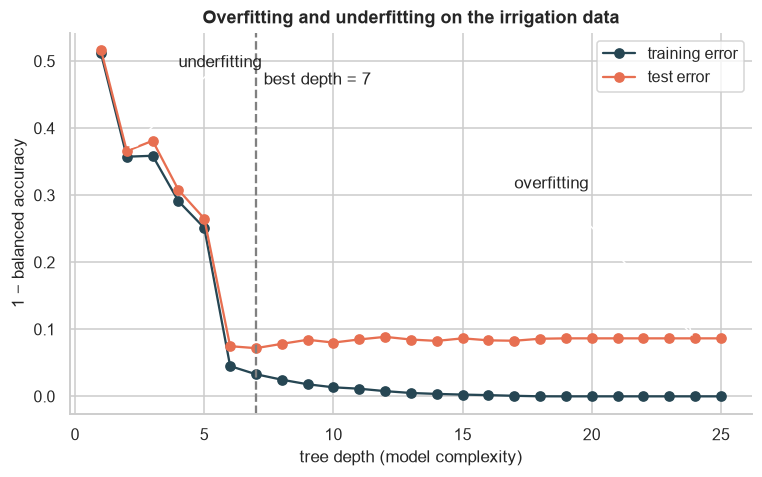

In [6]:
depths = range(1, 26)
train_err, test_err = [], []
for d in depths:
    m = DecisionTreeClassifier(max_depth=d, random_state=0).fit(X_train, y_train)
    train_err.append(1 - balanced_accuracy_score(y_train, m.predict(X_train)))
    test_err.append(1 - balanced_accuracy_score(y_test, m.predict(X_test)))

best = int(np.argmin(test_err)) + 1
fig, ax = plt.subplots()
ax.plot(depths, train_err, "o-", label="training error", color=plotting.ACCENT)
ax.plot(depths, test_err, "o-", label="test error", color="#e76f51")
ax.axvline(best, ls="--", color="grey")
ax.text(best + 0.3, max(test_err) * 0.9, f"best depth = {best}")
ax.annotate("underfitting", (2, test_err[1]), xytext=(4, max(test_err) * 0.95), arrowprops={"arrowstyle": "->"})
ax.annotate("overfitting", (24, test_err[23]), xytext=(17, max(test_err) * 0.6), arrowprops={"arrowstyle": "->"})
ax.set(xlabel="tree depth (model complexity)", ylabel="1 − balanced accuracy", title="Overfitting and underfitting on the irrigation data")
ax.legend()
plotting.save("g01-overfitting")
plt.show()

**Bias–variance trade-off.** The expected squared error of a model splits into *bias² + variance + noise*. Bias is how wrong the model is on average; variance is how much it changes when trained on a different sample. To measure them directly, the same model is trained on 30 different bootstrap samples and each test point's predictions are compared. Squared error needs a number, so the target here is the irrigation level as an ordinal score (Low = 0, Medium = 1, High = 2).

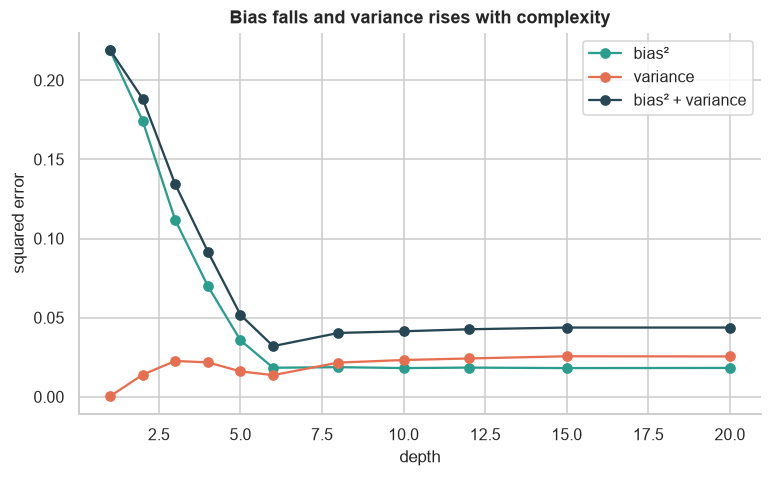

,bias²,variance,bias² + variance
depth,,,
1,0.219,0.000,0.219
2,0.174,0.014,0.188
3,0.112,0.023,0.134
4,0.070,0.022,0.092
5,0.036,0.016,0.052
6,0.018,0.014,0.032
8,0.019,0.022,0.040
10,0.018,0.023,0.041
12,0.018,0.024,0.043


In [7]:
from sklearn.tree import DecisionTreeRegressor

big = data.sample(40_000, seed=1)
Xb, yb = data.xy(big)
yb = yb.astype(float)
X_pts, y_pts = Xb.iloc[:2000], yb[:2000]
X_pool, y_pool = Xb.iloc[2000:], yb[2000:]
rng = np.random.default_rng(0)

rows = []
for d in [1, 2, 3, 4, 5, 6, 8, 10, 12, 15, 20]:
    preds = []
    for _ in range(30):
        i = rng.integers(0, len(X_pool), 3000)
        m = DecisionTreeRegressor(max_depth=d, random_state=0).fit(X_pool.iloc[i], y_pool[i])
        preds.append(m.predict(X_pts))
    preds = np.array(preds)
    mean_pred = preds.mean(axis=0)
    rows.append({"depth": d,
                 "bias²": np.mean((mean_pred - y_pts) ** 2),
                 "variance": np.mean(preds.var(axis=0))})
bv = pd.DataFrame(rows).set_index("depth")
bv["bias² + variance"] = bv.sum(axis=1)

ax = bv.plot(marker="o", color=["#2a9d8f", "#e76f51", plotting.ACCENT])
ax.set(ylabel="squared error", title="Bias falls and variance rises with complexity")
plotting.save("g01-bias-variance")
plt.show()
bv.round(3)

Bias drops quickly as the tree gets deeper while variance keeps growing, so their sum has a minimum at a moderate depth. That is the trade-off: simple models are biased, complex ones are unstable.

## 7. Applications and use cases

Irrigation scheduling is one of many: crop yield prediction, disease detection from leaf photos, demand forecasting, fraud detection, recommendations, speech and translation, medical imaging, and the LLM chatbots I've built on top of pretrained models. They follow the same workflow as section 5; only the data and the model family change.

## 8. NumPy for numerical computing

### Why NumPy?
Every library used here (pandas, scikit-learn, XGBoost) stores its data in NumPy arrays. A NumPy array is one block of memory of one type, and its operations run in compiled code instead of a Python loop.

In [8]:
import time
values = df["Rainfall_mm"].to_list() * 20
arr = np.array(values)

t = time.perf_counter(); total = sum(v * 0.001 for v in values); py_time = time.perf_counter() - t
t = time.perf_counter(); total_np = (arr * 0.001).sum(); np_time = time.perf_counter() - t
print(f"{len(values):,} values · Python loop {py_time*1000:.1f} ms · NumPy {np_time*1000:.2f} ms · {py_time/np_time:.0f}x faster")

400,000 values · Python loop 10.7 ms · NumPy 0.49 ms · 22x faster


### Creating arrays

In [9]:
print(np.array([[1, 2, 3], [4, 5, 6]]))
print(np.zeros((2, 3)), np.ones(3), np.full(2, 7.5), sep="\n")
print(np.arange(0, 1, 0.25), np.linspace(0, 1, 5))
print(np.eye(3))
soil = df[["Soil_pH", "Soil_Moisture", "Organic_Carbon"]].to_numpy()
print("from the data:", soil.shape, soil.dtype)

[[1 2 3]
 [4 5 6]]
[[0. 0. 0.]
 [0. 0. 0.]]
[1. 1. 1.]
[7.5 7.5]
[0.   0.25 0.5  0.75] [0.   0.25 0.5  0.75 1.  ]
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
from the data: (20000, 3) float64


### Operations on arrays

In [10]:
print("mean per column", soil.mean(axis=0).round(2))
print("max per column ", soil.max(axis=0))
print("element-wise   ", (soil[:3] * 2).round(2).tolist())
print("boolean mask   ", (soil[:, 1] < 20).sum(), "fields with moisture below 20%")
print("fancy indexing ", soil[[0, 5, 9], 1])
print("reshape        ", np.arange(12).reshape(3, 4).T.shape)

mean per column [ 6.49 37.28  0.92]
max per column  [ 8.2  64.99  1.6 ]
element-wise    [[12.44, 111.52, 0.92], [13.76, 75.92, 2.8], [15.78, 24.4, 0.62]]
boolean mask    3863 fields with moisture below 20%
fancy indexing  [55.76 59.53 61.05]
reshape         (4, 3)


### The broadcasting rule

Two arrays can be combined when, comparing their shapes from the right, each pair of dimensions is equal or one of them is 1. The dimension of size 1 is stretched without copying. That is how a whole matrix gets standardised in one line:

In [11]:
mu = soil.mean(axis=0)        # shape (3,)
sd = soil.std(axis=0)         # shape (3,)
z = (soil - mu) / sd          # (20000, 3) with (3,) -> broadcast across rows
print(z.shape, z.mean(axis=0).round(6), z.std(axis=0).round(6))

col = np.array([[1], [2], [3]])   # (3, 1)
row = np.array([10, 20, 30, 40])  # (4,)
print((col + row).shape)          # (3, 4)
try:
    np.ones((3, 2)) + np.ones(3)
except ValueError as err:
    print("not broadcastable:", err)

(20000, 3) [-0.  0. -0.] [1. 1. 1.]
(3, 4)
not broadcastable: operands could not be broadcast together with shapes (3,2) (3,) 


### Matrix operations

In [12]:
A = np.array([[2.0, 1.0], [1.0, 3.0]])
b = np.array([1.0, 2.0])
print("A @ b        ", A @ b)
print("transpose    ", A.T.tolist())
print("determinant  ", np.linalg.det(A))
print("inverse      ", np.linalg.inv(A).round(3).tolist())
print("solve Ax = b ", np.linalg.solve(A, b))

# least squares fit of moisture from temperature, the matrix way
Xd = np.column_stack([np.ones(len(df)), df["Temperature_C"]])
w = np.linalg.solve(Xd.T @ Xd, Xd.T @ df["Soil_Moisture"])
print("normal equation: moisture ≈ %.2f + %.3f × temperature" % tuple(w))

A @ b         [4. 7.]
transpose     [[2.0, 1.0], [1.0, 3.0]]
determinant   5.000000000000001
inverse       [[0.6, -0.2], [-0.2, 0.4]]
solve Ax = b  [0.2 0.6]
normal equation: moisture ≈ 39.24 + -0.073 × temperature


### The random module

In [13]:
rng = np.random.default_rng(42)            # seeded: same numbers every run
print(rng.integers(1, 7, 10))              # dice
print(rng.normal(25, 5, 5).round(2))       # temperatures
print(rng.choice(data.CLASSES, 10, p=[0.587, 0.379, 0.034]))
idx = rng.permutation(len(df))[:5]          # shuffled row order, as train_test_split does
print(idx)
print(np.random.default_rng(42).integers(1, 7, 10))  # same seed, same sequence

[1 5 4 3 3 6 1 5 2 1]
[18.49 25.64 23.42 24.92 20.73]
['Low' 'Medium' 'Medium' 'Medium' 'Low' 'Low' 'Low' 'Low' 'Medium'
 'Medium']
[ 5630 10868 13525 10590  8414]
[1 5 4 3 3 6 1 5 2 1]


## Summary

| Syllabus topic | Where |
|---|---|
| Introduction, AI vs ML vs DS | sections 1–2 |
| Supervised, unsupervised, reinforcement | section 3 |
| Parametric vs non-parametric, generative vs discriminative | section 4 |
| ML workflow | section 5 |
| Train–test split, metrics, overfitting, bias–variance | section 6 |
| Applications | section 7 |
| NumPy: why, creating, operations, broadcasting, matrices, random | section 8 |